# 01 - Exploratory Data Analysis (ApacheJIT)

**Goal:** get to know the ApacheJIT data before any modeling: its size, its columns, the label balance, the data quality, and how the labels change over time.

**Data:** `apachejit_total.csv` from the ApacheJIT replication package (Keshavarz & Nagappan, MSR 2022). It has 106,674 commits from open-source Apache Java projects, each labeled as bug-inducing or clean.

**Questions this notebook answers**
1. How big is the data, and what do the columns mean?
2. How imbalanced are the labels, and does this differ across projects?
3. Is the data clean (missing values, duplicates)?
4. Is the share of bug-inducing commits stable over time? (This decides how we split train and test.)
5. Which columns may safely be used as features? (The `fix` column may not; see section 4.)

## 0. Setup

Import the libraries and check what is inside the raw data folder. The downloaded package is expected in a folder named `apachejit_dataset_replication`.

In [9]:
from pathlib import Path
import pandas as pd

print(list(Path("../data/raw").glob("*")))

[WindowsPath('../data/raw/.gitkeep'), WindowsPath('../data/raw/apachejit_dataset_replication')]


## 1. Load the data

**Goal:** load the full dataset and check that it is complete: size, column names and the time range.

The file we use is `apachejit_total.csv` (all commits). The train and test files that come with the package are not used here, because we build our own time-based split later.

In [10]:
df = pd.read_csv("../data/raw/apachejit_dataset_replication/apachejit/dataset/apachejit_total.csv")

print(df.shape)
print(df.columns.tolist())
print(df["year"].min(), df["year"].max())
df.head()

(106674, 18)
['commit_id', 'project', 'buggy', 'fix', 'year', 'author_date', 'la', 'ld', 'nf', 'nd', 'ns', 'ent', 'ndev', 'age', 'nuc', 'aexp', 'arexp', 'asexp']
2003 2019


,commit_id,project,buggy,fix,year,author_date,la,ld,nf,nd,ns,ent,ndev,age,nuc,aexp,arexp,asexp
0,7b8480744ea6e6fb41efd4329bb470c8f3c763db,apache/groovy,False,False,2003,1070355653,372,23,8,3,3,2.669743,0.250000,3.625000,2.125,243,243.0,0.683585
1,192b631e7be302ecde822546ba70a9853ddbda01,apache/groovy,False,False,2003,1063298262,2,2,2,2,1,1.000000,1.000000,0.000000,2.500,19,19.0,14.000000
2,0ab6465a7dece117c61c3efd3ec95d20524bdad6,apache/groovy,False,False,2003,1069704572,41,26,3,3,2,1.237612,0.666667,5.333333,45.000,233,233.0,0.000606
3,449241d5fa1aeadd5eb9fa1280d4104dc0dfb891,apache/groovy,False,False,2003,1068487625,8,6,2,1,1,0.591673,1.000000,3.000000,35.500,64,64.0,55.000000
4,698df9f5b0816e05bbf97a390428f8ef94e0cdbf,apache/groovy,False,False,2003,1063313516,70,4,6,3,1,2.519672,0.333333,0.000000,6.000,27,27.0,22.000000


**Observation:** the table has 106,674 rows and 18 columns, and covers the years 2003 to 2019. Both match the paper, so the file is complete.

| Column | Role | Meaning |
|---|---|---|
| `commit_id` | identifier | commit hash; not a feature |
| `project` | group | source repository |
| `buggy` | **label** | True if the commit was found to be bug-inducing |
| `fix` | analysis only | marks fixing commits of fixed bug reports; always False for clean commits by construction; not used as a feature (see section 4) |
| `year` | time | year of the commit |
| `author_date` | time | commit time as a Unix timestamp (seconds); used for ordering |
| `la`, `ld` | feature | lines added / lines deleted |
| `nf`, `nd`, `ns` | feature | files / directories / subsystems touched |
| `ent` | feature | entropy (spread) of the change |
| `ndev` | feature | number of distinct developers who touched the files |
| `age` | feature | average time since the files were last changed |
| `nuc` | feature | number of unique changes to the files |
| `aexp`, `arexp`, `asexp` | feature | author experience / recent experience / subsystem experience |

## 2. Label balance and data quality

**Goal:** see how many commits are bug-inducing, whether this differs across projects, and whether the data has missing values or duplicates.

The cell prints, in order: the label counts, the share of bug-inducing commits, a per-project table (`count` = number of commits, `mean` = share of bug-inducing commits), and two quality numbers (missing cells, duplicated commit ids). A bar chart then shows the share of bug-inducing commits for each project; the red dashed line is the overall share.

In [11]:
print(df["buggy"].value_counts())
print(df["buggy"].mean())

print(df.groupby("project")["buggy"].agg(["count", "mean"]).round(2))

print(df.isna().sum().sum(), df["commit_id"].duplicated().sum())

buggy
False    78435
True     28239
Name: count, dtype: int64
0.26472242533325835
                         count  mean
project                             
apache/activemq           6126  0.23
apache/camel             22700  0.14
apache/cassandra          8159  0.38
apache/flink             11691  0.24
apache/groovy             8059  0.20
apache/hadoop            11964  0.00
apache/hadoop-hdfs        2907  0.76
apache/hadoop-mapreduce   1321  0.63
apache/hbase              8730  0.43
apache/hive               6842  0.62
apache/ignite            12036  0.20
apache/kafka              2384  0.47
apache/spark              1465  0.43
apache/zeppelin           1451  0.43
apache/zookeeper           839  0.41
0 0


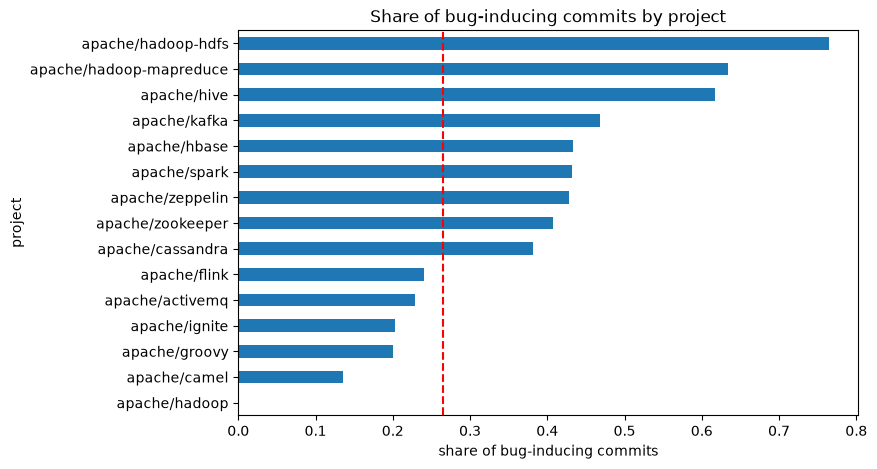

In [12]:
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

share_by_project = df.groupby("project")["buggy"].mean().sort_values()
ax = share_by_project.plot(kind="barh", figsize=(8, 5), title="Share of bug-inducing commits by project")
ax.axvline(df["buggy"].mean(), color="red", linestyle="--")
ax.set_xlabel("share of bug-inducing commits")
ax.figure.savefig("../reports/figures/01_share_by_project.png", dpi=150, bbox_inches="tight")

**Observation**
- There are 78,435 clean and 28,239 bug-inducing commits (about 26.5%), exactly as in the paper.
- A model that always predicts "clean" would reach about 73.5% accuracy, so accuracy is not a useful main metric. We will use F1, MCC, PR-AUC and effort-aware metrics instead.
- The share of bug-inducing commits depends strongly on the project: from about 14% (Camel) to about 76% (Hadoop HDFS).
- `apache/hadoop` (11,964 commits) has almost no bug-inducing commits. The three Hadoop names (`hadoop`, `hadoop-hdfs`, `hadoop-mapreduce`) add up to 16,192 commits, which equals the HDFS and MapReduce rows of the paper together. We therefore treat them as one group in per-project analysis. The reason for the split in the file is not explained in the paper.
- There are no missing values and no duplicated commit ids (the last line prints `0 0`).

## 3. Do labels change over time?

**Goal:** check whether the share of bug-inducing commits is stable across years. This matters because we want to train on older commits and test on newer ones, and unstable labels would make that comparison unfair.

The table shows, for each year, the number of commits (`count`) and the share of bug-inducing commits (`mean`). `.to_string()` prints the whole table without hiding the middle rows. A two-panel bar chart below the table shows the same numbers: commits per year (top) and the share of bug-inducing commits (bottom).

In [13]:
print(df.groupby("year")["buggy"].agg(["count", "mean"]).round(2).to_string())

      count  mean
year             
2003    295  0.06
2004    517  0.07
2005    717  0.10
2006   1417  0.12
2007   2331  0.15
2008   3218  0.18
2009   5305  0.26
2010   4973  0.40
2011   7117  0.32
2012   6923  0.33
2013   7001  0.37
2014  12319  0.27
2015  13824  0.30
2016  10606  0.29
2017  10187  0.27
2018   9365  0.21
2019  10559  0.10


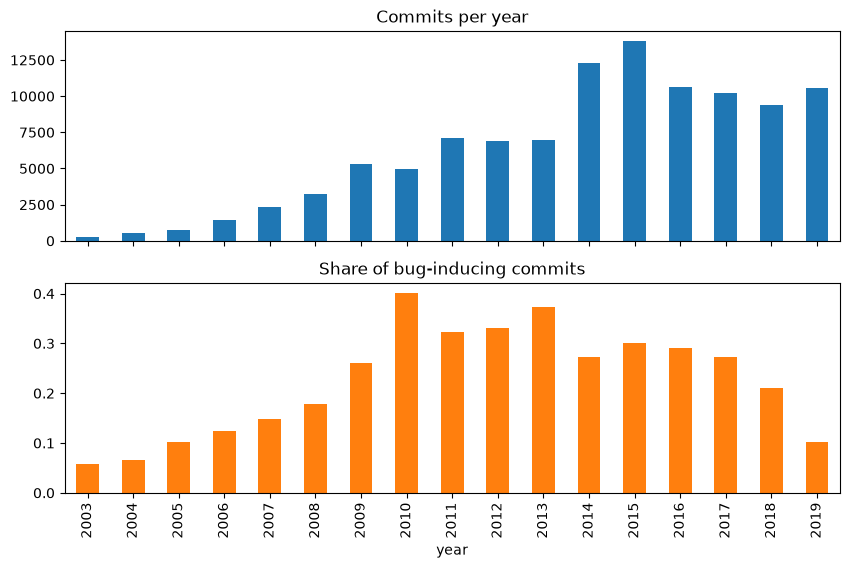

In [14]:
by_year = df.groupby("year")["buggy"].agg(["count", "mean"])
axes = by_year.plot(kind="bar", subplots=True, figsize=(10, 6), legend=False,
                    title=["Commits per year", "Share of bug-inducing commits"])
axes[0].figure.savefig("../reports/figures/01_label_drift_by_year.png", dpi=150, bbox_inches="tight")

**Observation:** the share of bug-inducing commits is not stable. It falls into three periods:

| Period | Commits | Share bug-inducing | Comment |
|---|---|---|---|
| 2003-2009 | about 13,800 | 6% rising to 26% | few commits, likely under-labeled |
| 2010-2017 | about 72,950 | 27% to 40% (about 31% overall) | most stable period |
| 2018-2019 | about 19,900 | 21% and 10% | labels likely incomplete |

Likely reasons (from the paper's construction process):
- Bug reports were collected only for 2010 to 2019, so early commits are under-labeled.
- A commit is labeled bug-inducing only after a later fix links back to it. Recent commits had less time to be linked, so some are probably labeled clean by mistake.

**Implication:** 2018-2019 is a risky test period, and the earliest years may add label noise to training. The split points are decided in section 7 using commit counts and label shares only, never model results.

## 3b. Project coverage over time

**Goal:** check when each project starts and ends, and merge the three Hadoop repository names into one group. This tells us whether one global time split works for every project.

The cell adds two temporary columns: `date` (readable commit date) and `group` (project name with the Hadoop repositories merged). The CSV file is not changed.

In [15]:
df["date"] = pd.to_datetime(df["author_date"], unit="s")

df["group"] = df["project"].replace({
    "apache/hadoop": "hadoop",
    "apache/hadoop-hdfs": "hadoop",
    "apache/hadoop-mapreduce": "hadoop",
})

print(df.groupby("group")["date"].agg(["min", "max", "count"]))

                                 min                 max  count
group                                                          
apache/activemq  2005-12-12 17:57:25 2019-12-11 14:05:50   6126
apache/camel     2007-03-19 10:54:57 2019-12-26 11:31:48  22700
apache/cassandra 2009-03-02 23:34:21 2019-12-09 15:32:35   8159
apache/flink     2010-12-17 15:07:10 2019-12-26 07:37:50  11691
apache/groovy    2003-09-11 14:54:46 2019-12-25 10:49:51   8059
apache/hbase     2007-04-06 21:09:28 2019-12-25 20:38:02   8730
apache/hive      2008-09-09 17:36:23 2019-12-20 13:55:26   6842
apache/ignite    2014-02-20 12:09:51 2019-12-26 12:17:11  12036
apache/kafka     2011-10-06 19:48:03 2019-12-20 01:05:19   2384
apache/spark     2010-12-06 05:20:15 2019-12-26 17:39:53   1465
apache/zeppelin  2013-08-15 11:57:35 2019-12-20 14:52:21   1451
apache/zookeeper 2007-11-06 17:15:39 2019-12-03 18:12:30    839
hadoop           2009-05-19 04:37:10 2019-12-25 05:37:25  16192


**Observation:** the merged `hadoop` group has 16,192 commits, equal to the sum of the three repository names, so the merge worked. All 13 groups (12 projects plus Hadoop) have commits until December 2019, so each of them appears in the validation and test years. Most projects start between 2003 and 2011; Ignite (Feb 2014) and Zeppelin (Aug 2013) are the youngest, with only about two years of history before 2016. A single global time split is therefore workable.

Small projects (ZooKeeper 839, Zeppelin 1,451, Spark 1,465 commits) will have very few test commits, so their per-project results are noisy and will be reported with caution.

## 4. The `fix` column

**Goal:** understand what `fix` means and decide whether it may be used as a feature. A feature is allowed only if it is known at commit time and does not depend on how the labels were built.

The cell prints how many commits have `fix=True`, a count table of `fix` against `buggy`, and the same table as row percentages.

In [16]:
print(df["fix"].value_counts())
print(pd.crosstab(df["fix"], df["buggy"]))
print(pd.crosstab(df["fix"], df["buggy"], normalize="index").round(2))

fix
False    95984
True     10690
Name: count, dtype: int64
buggy  False  True 
fix                
False  75508  20476
True    2927   7763
buggy  False  True 
fix                
False   0.79   0.21
True    0.27   0.73


**Observation:** `fix=True` marks commits identified as fixing commits of fixed bug reports (10,690 commits, about 10%). All 75,508 clean commits have `fix=False` by construction: the dataset construction notebook sets `fix` to False for every clean commit, and the paper removes fixing commits with bug-inducing links from the clean pool.

| | clean | bug-inducing | share bug-inducing |
|---|---|---|---|
| fix = False | 75,508 | 20,476 | 21% |
| fix = True | 2,927 | 7,763 | 73% |

**Decision:** `fix` is **not used as a feature**. Its strong link to the label (73% vs 21%) is mostly a side effect of how the clean class was sampled, and it is not reliably known at commit time (it depends on a later fix and on the issue being closed). We keep the column for analysis only.

## 5. Feature distributions

**Goal:** understand the 12 numeric features before modeling: their ranges, how many values are zero, how skewed they are, and whether any values look impossible. The answers decide which features need a transformation (for example a log transform for logistic regression) and whether scaling is needed.

The first cell builds one table with the usual statistics (`count`, `mean`, `std`, `min`, quartiles, `max`) plus two extra columns: `skew` (a value far above 1 means a long tail of very large values) and `share_zero` (the share of commits where the feature is 0). The list `features` is reused in later sections.

In [17]:
features = ["la", "ld", "nf", "nd", "ns", "ent", "ndev", "age", "nuc", "aexp", "arexp", "asexp"]

summary = df[features].describe().T
summary["skew"] = df[features].skew()
summary["share_zero"] = (df[features] == 0).mean()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,share_zero
la,106674.0,189.13,533.16,0.0,7.00,37.00,147.00,9967.00,7.77,0.03
ld,106674.0,76.73,312.68,0.0,2.00,9.00,41.00,9950.00,12.89,0.13
nf,106674.0,6.36,10.14,1.0,1.00,3.00,7.00,100.00,4.13,0.00
nd,106674.0,2.94,3.42,1.0,1.00,2.00,3.00,89.00,4.68,0.00
ns,106674.0,1.42,0.98,1.0,1.00,1.00,2.00,45.00,6.15,0.00
ent,106674.0,1.30,1.24,0.0,0.00,1.00,2.05,6.57,0.93,0.28
ndev,106674.0,5.23,9.11,0.0,1.00,2.33,5.88,167.50,5.80,0.03
age,106674.0,60.33,136.15,0.0,1.33,13.82,57.00,2713.06,5.65,0.19
nuc,106674.0,90.91,251.27,0.0,5.00,15.00,51.00,3704.50,5.60,0.03
aexp,106674.0,1225.43,2704.08,0.0,49.00,222.00,829.00,15795.00,3.32,0.02


**Sanity check:** by definition a commit cannot touch more directories than files (`nd` <= `nf`), or more subsystems than directories (`ns` <= `nd`). The cell prints how many commits break each rule.

In [18]:
print((df["nd"] > df["nf"]).sum(), (df["ns"] > df["nd"]).sum())

0 1363


**Distributions:** one histogram per feature. Values above the 99th percentile are capped, so the bulk of the data is visible; the right-most bar of each chart therefore also contains those capped extreme values.

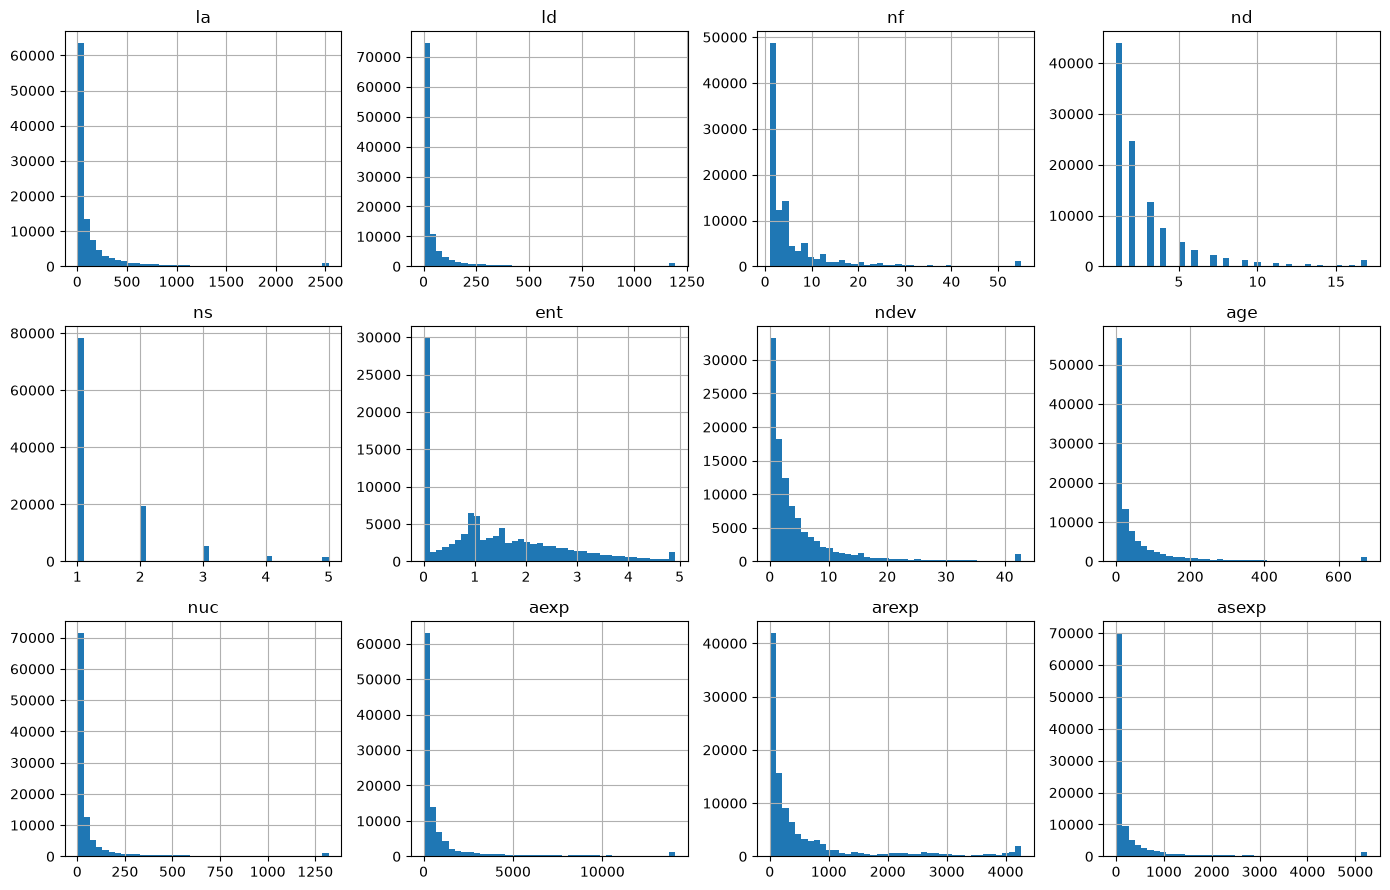

In [19]:
caps = df[features].quantile(0.99)
axes = df[features].clip(upper=caps, axis=1).hist(bins=40, figsize=(14, 9), layout=(3, 4))
axes[0, 0].figure.tight_layout()
axes[0, 0].figure.savefig("../reports/figures/01_feature_distributions.png", dpi=150, bbox_inches="tight")

**Observation**
- All features are non-negative (no impossible values). The maxima match the paper's filters: at most 100 files per commit, and fewer than 10,000 lines added or deleted.
- Almost all features have a long right tail: the mean is far above the median and `skew` is above 2 for 11 of 12 features (`la` 7.8, `ld` 12.9, `ns` 6.2, `ndev` 5.8, `age` 5.7, `nuc` 5.6). Only `ent` is closer to symmetric (0.93).
- Many values are exactly zero for `ent` (28%), `age` (19%) and `ld` (13%).
- `nf`, `nd` and `ns` are small whole numbers. `ent` has a spike at zero and a broad spread up to about 5.
- Sanity check: no commit has more directories than files, but 1,363 commits (1.3%) have more subsystems than directories. The cause is unknown; the share is small, so we keep these rows.
- The 99th-percentile capping was used only for the charts; the data itself is unchanged.

**Decisions**
- No rows are removed and no values are changed.
- Tree models (Random Forest, XGBoost, LightGBM) use the raw features, because monotonic transforms do not change their splits.
- Logistic Regression uses `log1p` on the 11 skewed features (all except `ent`; possible because all values are >= 0), then standardization of all features. The scaler is fitted on the training period only, to avoid leaking information from validation and test.

## 6. Features versus label

**Goal:** see how bug-inducing and clean commits differ in their features, and which features carry overlapping information. This shows which features look useful on their own and which are redundant, which matters later when we read SHAP explanations.

Three cells follow: (1) the median of every feature for each class, (2) a bar chart of the Spearman correlation between each feature and the label, and (3) a correlation table between the features themselves (blue = negative, red = positive). Spearman uses ranks, so it works with the skewed features without transforming them.

In [20]:
medians = df.groupby("buggy")[features].median().T
medians.columns = ["clean", "bug-inducing"]
medians.round(2)

,clean,bug-inducing
la,22.00,138.00
ld,6.00,27.00
nf,2.00,6.00
nd,2.00,3.00
ns,1.00,1.00
ent,0.92,1.77
ndev,2.50,2.00
age,11.17,19.50
nuc,13.00,22.61
aexp,241.00,180.00


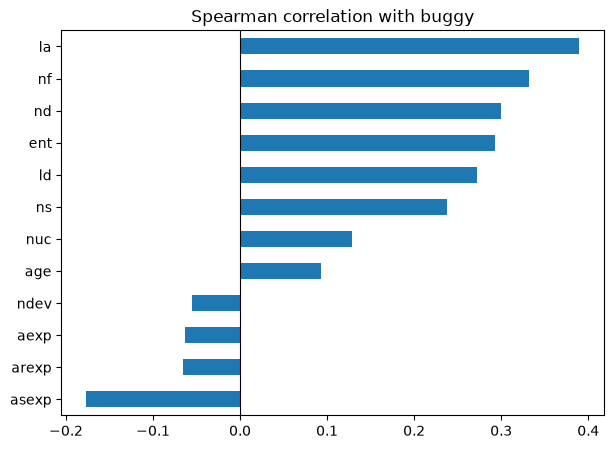

In [21]:
corr_label = df[features].corrwith(df["buggy"].astype(int), method="spearman").sort_values()
ax = corr_label.plot(kind="barh", figsize=(7, 5), title="Spearman correlation with buggy")
ax.axvline(0, color="black", linewidth=0.8)
ax.figure.savefig("../reports/figures/01_corr_with_label.png", dpi=150, bbox_inches="tight")

In [22]:
corr = df[features].corr(method="spearman")
corr.round(2).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,la,ld,nf,nd,ns,ent,ndev,age,nuc,aexp,arexp,asexp
la,1.000000,0.490000,0.720000,0.580000,0.310000,0.650000,-0.310000,0.130000,-0.020000,-0.130000,-0.140000,-0.260000
ld,0.490000,1.000000,0.610000,0.500000,0.270000,0.560000,-0.200000,0.160000,0.040000,-0.060000,-0.060000,-0.190000
nf,0.720000,0.610000,1.000000,0.850000,0.460000,0.960000,-0.340000,0.220000,0.080000,-0.100000,-0.100000,-0.340000
nd,0.580000,0.500000,0.850000,1.000000,0.540000,0.800000,-0.170000,0.190000,0.210000,-0.090000,-0.090000,-0.380000
ns,0.310000,0.270000,0.460000,0.540000,1.000000,0.430000,0.000000,0.130000,0.240000,-0.070000,-0.070000,-0.690000
ent,0.650000,0.560000,0.960000,0.800000,0.430000,1.000000,-0.340000,0.220000,0.050000,-0.080000,-0.090000,-0.310000
ndev,-0.310000,-0.200000,-0.340000,-0.170000,0.000000,-0.340000,1.000000,0.110000,0.750000,-0.110000,-0.130000,-0.020000
age,0.130000,0.160000,0.220000,0.190000,0.130000,0.220000,0.110000,1.000000,0.090000,-0.070000,-0.090000,-0.120000
nuc,-0.020000,0.040000,0.080000,0.210000,0.240000,0.050000,0.750000,0.090000,1.000000,-0.020000,-0.030000,-0.110000
aexp,-0.130000,-0.060000,-0.100000,-0.090000,-0.070000,-0.080000,-0.110000,-0.070000,-0.020000,1.000000,0.990000,0.570000


**Observation**
- Size and spread features have the strongest single-feature link to the label: `la` (about 0.39), then `nf`, `nd`, `ent`, `ld` and `ns` (0.24 to 0.33). Bug-inducing commits are larger and more spread out: the median `la` is 138 vs 22 for clean commits, `nf` is 6 vs 2, `ent` is 1.77 vs 0.92.
- Experience features point the other way: `asexp` (about -0.18) is the strongest, with a median of 5 for bug-inducing vs 52 for clean commits; `aexp` and `arexp` are weaker (about -0.07). Authors with little experience in a subsystem tend to be linked to bug-inducing commits more often.
- `nuc` (0.13), `age` (0.09) and `ndev` (-0.06) are weak.
- No single feature is strong (the largest absolute correlation is about 0.39), so no feature separates the classes alone. We should expect modest scores, not near-perfect ones.
- Many features carry overlapping information. Strongest pairs: `nf`-`ent` 0.96, `nf`-`nd` 0.85, `nd`-`ent` 0.80, `ndev`-`nuc` 0.75, `la`-`nf` 0.72, `asexp`-`ns` -0.69.

**Decisions**
- Keep all 12 features for now; no manual removal at this stage.
- Read SHAP results by feature group, not one feature at a time, because correlated features share importance: size and spread (`la`, `ld`, `nf`, `nd`, `ns`, `ent`), experience (`aexp`, `arexp`, `asexp`) and file history (`ndev`, `age`, `nuc`).
- For Logistic Regression rely on regularization, and if time allows test a variant without `ent` (almost a duplicate of `nf`).

## 7. Time-split design

**Goal:** choose the train, validation and test periods. The cut points are chosen only from commit counts and label shares, never from model results, so that the evaluation stays honest.

Proposed split:
- **train:** 2003-2015, **validation:** 2016 (used to tune models), **test:** 2017 (used once, at the end).
- **late check:** 2018-2019, kept out of model selection and reported separately, because their labels are probably incomplete.

The cells show (1) the size and label share of each period, (2) how many commits each project has in each period, and (3) the same numbers for the split used by the dataset authors (train up to 2016, test from 2017), for comparison.

In [23]:
def period(year):
    if year <= 2015:
        return "train (2003-2015)"
    if year == 2016:
        return "validation (2016)"
    if year == 2017:
        return "test (2017)"
    return "late check (2018-2019)"

df["period"] = df["year"].apply(period)
order = ["train (2003-2015)", "validation (2016)", "test (2017)", "late check (2018-2019)"]

split_table = df.groupby("period")["buggy"].agg(["count", "mean"]).loc[order]
split_table["share_of_data"] = split_table["count"] / len(df)
split_table.round(3)

,count,mean,share_of_data
period,,,
train (2003-2015),65957,0.293,0.618
validation (2016),10606,0.291,0.099
test (2017),10187,0.272,0.095
late check (2018-2019),19924,0.153,0.187


In [24]:
pd.crosstab(df["group"], df["period"])[order]

period,train (2003-2015),validation (2016),test (2017),late check (2018-2019)
group,,,,
apache/activemq,5545,308,114,159
apache/camel,14158,2110,2130,4302
apache/cassandra,7006,599,284,270
apache/flink,5240,997,1139,4315
apache/groovy,6463,245,416,935
apache/hbase,5745,827,849,1309
apache/hive,3883,869,844,1246
apache/ignite,7226,1746,1657,1407
apache/kafka,293,451,636,1004


In [25]:
authors_test = df["year"] >= 2017
print(authors_test.mean().round(3), df.loc[authors_test, "buggy"].mean().round(3), df.loc[~authors_test, "buggy"].mean().round(3))

0.282 0.193 0.293


**Observation**
- Train (2003-2015) has 65,957 commits (62% of the data, 29.3% bug-inducing), validation (2016) has 10,606 (29.1%) and test (2017) has 10,187 (27.2%). The label shares are close, so scores on the three periods are comparable. Validation and test each contain roughly 2,800 to 3,100 bug-inducing commits, enough for stable estimates.
- The late-check years (2018-2019) have only 15.3% bug-inducing commits, which fits the incomplete-label explanation, so they are not used for model selection.
- Every project appears in every period, but the mix shifts. Kafka has only 293 training commits against 636 in the test year, and ZooKeeper has only 27 validation and 39 test commits; ActiveMQ (114) and Spark (186) also have few test commits. Hadoop has just 412 commits in 2018-2019.
- The dataset authors' split (train up to 2016, test from 2017) puts 28.2% of the data in test, with only 19.3% bug-inducing commits against 29.3% in train. The test share is diluted by 2018-2019, so precision-based scores from that split are not comparable with ours.

**Decisions**
- Use train 2003-2015, validation 2016, test 2017, and report 2018-2019 separately as a late-label check.
- After tuning on validation, refit the final model on 2003-2016 and evaluate it once on 2017.
- Report per-project results only for projects with at least 200 test commits (this excludes ActiveMQ, Spark and ZooKeeper); all projects stay in training and in the pooled evaluation.
- The authors' split is an optional robustness check; because prevalence differs, compare it with ours using ROC-AUC (less sensitive to prevalence) rather than precision-based scores.

## Summary and decisions (so far)

- Keep all 106,674 rows; the data is complete and clean.
- Label: `buggy` (about 26.5% positive). Do not use accuracy as the main metric.
- Time: order commits by `author_date` and use a time-based split instead of a random split.
- Treat `hadoop`, `hadoop-hdfs` and `hadoop-mapreduce` as one group in per-project analysis.
- `fix` is excluded from the features (see section 4).
- Time split: train 2003-2015, validation 2016, test 2017; 2018-2019 is a separate late-label check (section 7). The final model is refit on 2003-2016 before the single test evaluation.
- Per-project results only for projects with at least 200 test commits (not ActiveMQ, Spark, ZooKeeper).
- Features: all 12 are non-negative and right-skewed. Trees use raw values; Logistic Regression uses `log1p` (all but `ent`) plus standardization fitted on the training period only.
- Data quirk: 1.3% of commits have more subsystems than directories (`ns` > `nd`); rows are kept.
- Strongest single signals: change size and spread (`la`, `nf`, `nd`, `ent`, `ld`, `ns`) and low subsystem experience (`asexp`); no single feature is strong (absolute correlation at most about 0.4).
- Features overlap (for example `aexp`-`arexp` 0.99, `nf`-`ent` 0.96); all are kept and SHAP is read by feature group.

**Next:** `02_split_and_baseline.ipynb` - implement this split in `src/data/` and train the first baseline (logistic regression).